In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [5]:
column = ['label', 'message', 'col3', 'col4', 'col5']
df_sms = pd.read_csv('sms_spam_collection.csv', encoding='ISO-8859-1')
df_sms.columns = column
df_sms.drop(['col3', 'col4', 'col5'], axis=1, inplace=True)
df_sms

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


# Text Preprocessing 1

> ## Converting to lower case

In [6]:
# lowercase
def to_lower(text):
    return text.lower()

text_string = "Summerland in 2024"
text_string_lower = to_lower(text_string)
text_string_lower

'summerland in 2024'

> ## Contraction

- I’ve done it → I have done it 
- I’m here → I am here
- You’re smart → You are smart

In [7]:
import re

In [8]:
contractions_dict = {     
"ain't": "am not",
"aren't": "are not",
"can't": "cannot",
"can't've": "cannot have",
"'cause": "because",
"could've": "could have",
"couldn't": "could not",
"couldn't've": "could not have",
"didn't": "did not",
"doesn't": "does not",
"don't": "do not",
"hadn't": "had not",
"hadn't've": "had not have",
"hasn't": "has not",
"haven't": "have not",
"he'd": "he had",
"he'd've": "he would have",
"he'll": "he will",
"he'll've": "he will have",
"he's": "he is",
"how'd": "how did",
"how'd'y": "how do you",
"how'll": "how will",
"how's": "how is",
"I'd": "I had",
"I'd've": "I would have",
"I'll": "I will",
"I'll've": "I will have",
"I'm": "I am",
"I've": "I have",
"isn't": "is not",
"it'd": "it had",
"it'd've": "it would have",
"it'll": "it will",
"it'll've": "iit will have",
"it's": "it is",
"let's": "let us",
"ma'am": "madam",
"mayn't": "may not",
"might've": "might have",
"mightn't": "might not",
"mightn't've": "might not have",
"must've": "must have",
"mustn't": "must not",
"mustn't've": "must not have",
"needn't": "need not",
"needn't've": "need not have",
"o'clock": "of the clock",
"oughtn't": "ought not",
"oughtn't've": "ought not have",
"shan't": "shall not",
"sha'n't": "shall not",
"shan't've": "shall not have",
"she'd": "she had",
"she'd've": "she would have",
"she'll": "she will",
"she'll've": "she will have",
"she's": "she is",
"should've": "should have",
"shouldn't": "should not",
"shouldn't've": "should not have",
"so've": "so have",
"so's": "so is",
"that'd": "that had",
"that'd've": "that would have",
"that's": "that is",
"there'd": "there had",
"there'd've": "there would have",
"there's": "there is",
"they'd": "they had",
"they'd've": "they would have",
"they'll": "they will",
"they'll've": "they will have",
"they're": "they are",
"they've": "they have",
"to've": "to have",
"wasn't": "was not",
"we'd": "we had",
"we'd've": "we would have",
"we'll": "we will",
"we'll've": "we will have",
"we're": "we are",
"we've": "we have",
"weren't": "were not",
"what'll": "what will",
"what'll've": "what will have",
"what're": "what are",
"what's": "what is",
"what've": "what have",
"when's": "when is",
"when've": "when have",
"where'd": "where did",
"where's": "where is",
"where've": "where have",
"who'll": "who will",
"who'll've": "who will have",
"who's": "who is",
"who've": "who have",
"why's": "why is",
"why've": "why have",
"will've": "will have",
"won't": "will not",
"won't've": "will not have",
"would've": "would have",
"wouldn't": "would not",
"wouldn't've": "would not have",
"y'all": "you all",
"y'all'd": "you all would",
"y'all'd've": "you all would have",
"y'all're": "you all are",
"y'all've": "you all have",
"you'd": "you had",
"you'd've": "you would have",
"you'll": "you will",
"you'll've": "you will have",
"you're": "you are",
"you've": "you have"
}

In [11]:
def expand_match(text):
        match = text.group(0)
        expanded_text = contractions_dict.get(match) \
            if contractions_dict.get(match) \
            else contractions_dict.get(match.lower())
        return expanded_text

def expand_contractions(text, contractions_dict):
    contractions_pattern = re.compile('({})'.format('|'.join(contractions_dict.keys())),
                                    flags=re.IGNORECASE | re.DOTALL)
    expanded_text = contractions_pattern.sub(expand_match, text)
    expanded_text = re.sub("'", "", expanded_text)
    return expanded_text

def main_contractions(text):
    text = expand_contractions(text, contractions_dict)
    return text

In [12]:
text_string = "If I ain't got you"
text_string_contractions = main_contractions(text_string)
text_string_contractions

'If I am not got you'

> ## Remove or Convert Number Into Text

In [13]:
def remove_numbers(text):
    output = ''.join(c for c in text if not c.isdigit())
    return output

text_string = "I was born in 1996"
text_string_number = remove_numbers(text_string)
text_string_number

'I was born in '

> ## Remove Punctuation

In [14]:
from string import punctuation

In [15]:
def remove_punct(text):
    return ''.join(c for c in text if c not in punctuation)

text_string = "There was bobby, alex, fergie and I"
text_string_punct = remove_punct(text_string)
text_string_punct

'There was bobby alex fergie and I'

> ## Remove White Spaces

In [20]:
def to_strip(text):
    return " ".join(text.split())

text_string = "There         was         bobby, alex,        fergie and I"
text_string_strip = to_strip(text_string)
text_string_strip

'There was bobby, alex, fergie and I'

> ## Remove Stop Words and Particular Words

In [21]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to C:\Users\Lenovo
[nltk_data]     Flex\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt to C:\Users\Lenovo
[nltk_data]     Flex\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.


True

In [22]:
stopwords.words('english')

['i',
 'me',
 'my',
 'myself',
 'we',
 'our',
 'ours',
 'ourselves',
 'you',
 "you're",
 "you've",
 "you'll",
 "you'd",
 'your',
 'yours',
 'yourself',
 'yourselves',
 'he',
 'him',
 'his',
 'himself',
 'she',
 "she's",
 'her',
 'hers',
 'herself',
 'it',
 "it's",
 'its',
 'itself',
 'they',
 'them',
 'their',
 'theirs',
 'themselves',
 'what',
 'which',
 'who',
 'whom',
 'this',
 'that',
 "that'll",
 'these',
 'those',
 'am',
 'is',
 'are',
 'was',
 'were',
 'be',
 'been',
 'being',
 'have',
 'has',
 'had',
 'having',
 'do',
 'does',
 'did',
 'doing',
 'a',
 'an',
 'the',
 'and',
 'but',
 'if',
 'or',
 'because',
 'as',
 'until',
 'while',
 'of',
 'at',
 'by',
 'for',
 'with',
 'about',
 'against',
 'between',
 'into',
 'through',
 'during',
 'before',
 'after',
 'above',
 'below',
 'to',
 'from',
 'up',
 'down',
 'in',
 'out',
 'on',
 'off',
 'over',
 'under',
 'again',
 'further',
 'then',
 'once',
 'here',
 'there',
 'when',
 'where',
 'why',
 'how',
 'all',
 'any',
 'both',
 'each

In [23]:
def remove_stopwords(text):
    stop_words = stopwords.words('english')
    return ' '.join([w for w in nltk.word_tokenize(text) if not w in stop_words])

In [26]:
text_string = "I love indonesia, so much, how about you?"
text_string_stopwords = remove_stopwords(text_string)
text_string_stopwords

'I love indonesia , much , ?'

> ## Combine Preprocessing Method

In [30]:
pd.options.display.max_colwidth = None

df_sms['message_prep1'] = df_sms['message'].apply(to_lower)
df_sms['message_prep2'] = df_sms['message_prep1'].apply(main_contractions)
df_sms['message_prep3'] = df_sms['message_prep2'].apply(remove_numbers)
df_sms['message_prep4'] = df_sms['message_prep3'].apply(remove_punct)
df_sms['message_prep5'] = df_sms['message_prep4'].apply(to_strip)
df_sms['message_prep6'] = df_sms['message_prep5'].apply(remove_stopwords)
df_sms.head(5)

,label,message,message_prep1,message_prep2,message_prep3,message_prep4,message_prep5,message_prep6
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...","go until jurong point, crazy.. available only in bugis n great world la e buffet... cine there got amore wat...","go until jurong point, crazy.. available only in bugis n great world la e buffet... cine there got amore wat...","go until jurong point, crazy.. available only in bugis n great world la e buffet... cine there got amore wat...",go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat,go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat,go jurong point crazy available bugis n great world la e buffet cine got amore wat
1,ham,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,ok lar... joking wif u oni...,ok lar... joking wif u oni...,ok lar joking wif u oni,ok lar joking wif u oni,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005. text fa to 87121 to receive entry question(std txt rate)t&c's apply 08452810075over18's,free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005. text fa to 87121 to receive entry question(std txt rate)t&cs apply 08452810075over18s,free entry in a wkly comp to win fa cup final tkts st may . text fa to to receive entry question(std txt rate)t&cs apply overs,free entry in a wkly comp to win fa cup final tkts st may text fa to to receive entry questionstd txt ratetcs apply overs,free entry in a wkly comp to win fa cup final tkts st may text fa to to receive entry questionstd txt ratetcs apply overs,free entry wkly comp win fa cup final tkts st may text fa receive entry questionstd txt ratetcs apply overs
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...,u dun say so early hor... u c already then say...,u dun say so early hor... u c already then say...,u dun say so early hor u c already then say,u dun say so early hor u c already then say,u dun say early hor u c already say
4,ham,"Nah I don't think he goes to usf, he lives around here though","nah i don't think he goes to usf, he lives around here though","nah i do not think he goes to usf, he lives around here though","nah i do not think he goes to usf, he lives around here though",nah i do not think he goes to usf he lives around here though,nah i do not think he goes to usf he lives around here though,nah think goes usf lives around though


# Text Preprocessing 2

> ## Stemming

In [31]:
from nltk.stem import SnowballStemmer

In [32]:
snowball_stemmer = SnowballStemmer('english')

def stem(text):
    stemmed_word = [snowball_stemmer.stem(word) for sent in nltk.sent_tokenize(text)for word in nltk.word_tokenize(sent)]
    return " ".join(stemmed_word)

text_string = "i am reading a book and the book is very fascinating"
text_string_stem = stem(text_string)
text_string_stem

'i am read a book and the book is veri fascin'

> ## Lemmatization

In [33]:
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet')

[nltk_data] Downloading package wordnet to C:\Users\Lenovo
[nltk_data]     Flex\AppData\Roaming\nltk_data...


True

In [34]:
wordnet_lemmatizer = WordNetLemmatizer()

def lemmatize(text):
    lemmatized_word = [wordnet_lemmatizer.lemmatize(word)for sent in nltk.sent_tokenize(text)for word in nltk.word_tokenize(sent)]
    return " ".join(lemmatized_word)

text_string = "there she goes. Here I am"
text_string_lemma = lemmatize(text_string)
text_string_lemma

'there she go . Here I am'

> ## Apply Stemming or Lemmatization 

In [37]:
df_sms['message_prep_stem'] = df_sms['message_prep6'].apply(stem)
df_sms['message_prep_lemma'] = df_sms['message_prep6'].apply(lemmatize)

df_sms[['message_prep_stem','message_prep_lemma']].head()

,message_prep_stem,message_prep_lemma
0,go jurong point crazi avail bugi n great world la e buffet cine got amor wat,go jurong point crazy available bugis n great world la e buffet cine got amore wat
1,ok lar joke wif u oni,ok lar joking wif u oni
2,free entri wkli comp win fa cup final tkts st may text fa receiv entri questionstd txt ratetc appli over,free entry wkly comp win fa cup final tkts st may text fa receive entry questionstd txt ratetcs apply over
3,u dun say earli hor u c alreadi say,u dun say early hor u c already say
4,nah think goe usf live around though,nah think go usf life around though


# Text Exploration

> ## Word Freq

In [38]:
def freq_check(text):
    text = text.str.extractall('([a-zA_Z]+)')
    text.columns = ['text']
    b = text.reset_index(drop=True)
    text = b['text'].value_counts()

    temp = {'word':text.index,'freq':text.values}
    temp = pd.DataFrame(temp)
    temp.index = temp['word']
    temp.drop('word', axis = 1, inplace = True)
    temp.sort_values('freq',ascending=False,inplace=True)
    
    return temp

In [39]:
df_sms.shape

(5572, 10)

In [40]:
freq_unclean = freq_check(df_sms['message_prep_lemma'])
freq_unclean

,freq
word,
u,1213
call,603
get,401
ur,384
go,308
...,...
twinks,1
scallies,1
cop,1


<Axes: ylabel='word'>

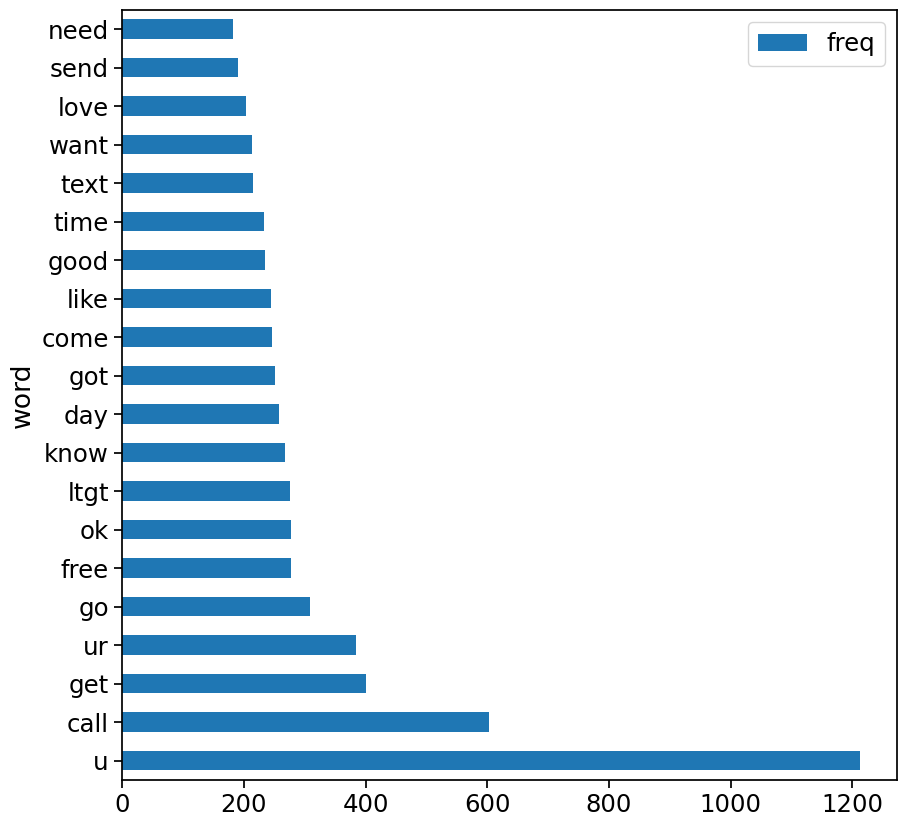

In [41]:
sns.set_context(context = 'notebook', font_scale = 1.6)
freq_unclean[:20].plot(kind = 'barh',figsize = (10,10))

> ## Word Cloud

In [58]:
from wordcloud import WordCloud

In [59]:
def plot_cloud(wordcloud):
    # Set figure size
    plt.figure(figsize=(20, 10))
    # Display image
    plt.imshow(wordcloud) 
    # No axis details
    plt.axis("off")

In [60]:
word_cloud = WordCloud().generate(str(df_sms['message_prep_lemma']))

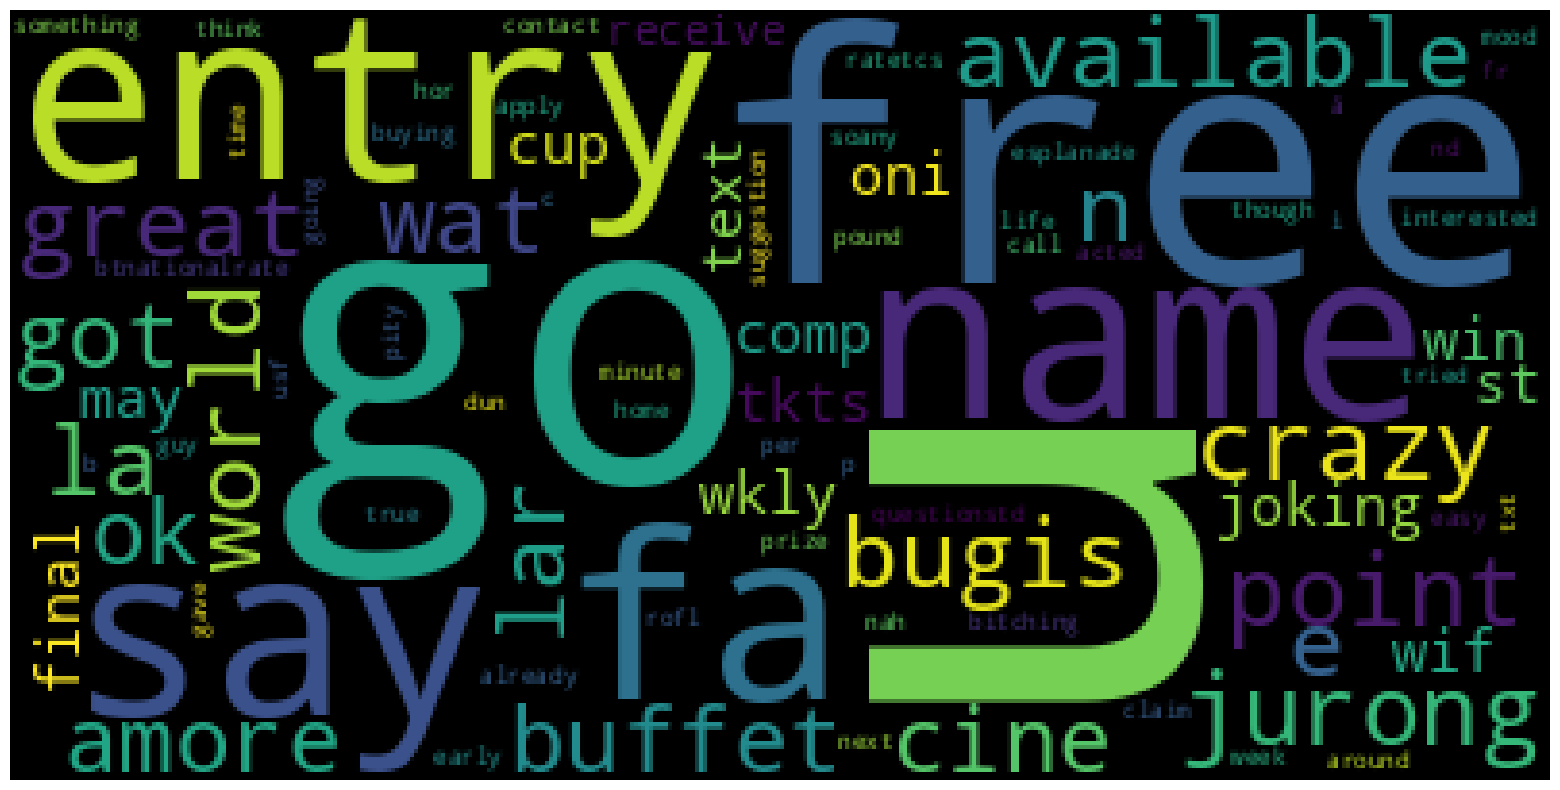

In [61]:
plot_cloud(word_cloud)

> ## Word Cloud 2

In [62]:
from PIL import Image

In [71]:
cat_mask = np.array(Image.open('cat.jpg'))
spam_mask = np.array(Image.open('man-in-chair-reading.png'))
non_spam_mask = np.array(Image.open('alice.jpg'))

In [72]:
wordcloud = WordCloud(  
                        random_state=1, 
                        max_font_size=300,
                        max_words=2000,
                        background_color='white', 
                        colormap='Set2', 
                        collocations=False, 
                        stopwords = stopwords.words('english'), 
                        mask=cat_mask).generate(str(df_sms['message_prep_lemma']))

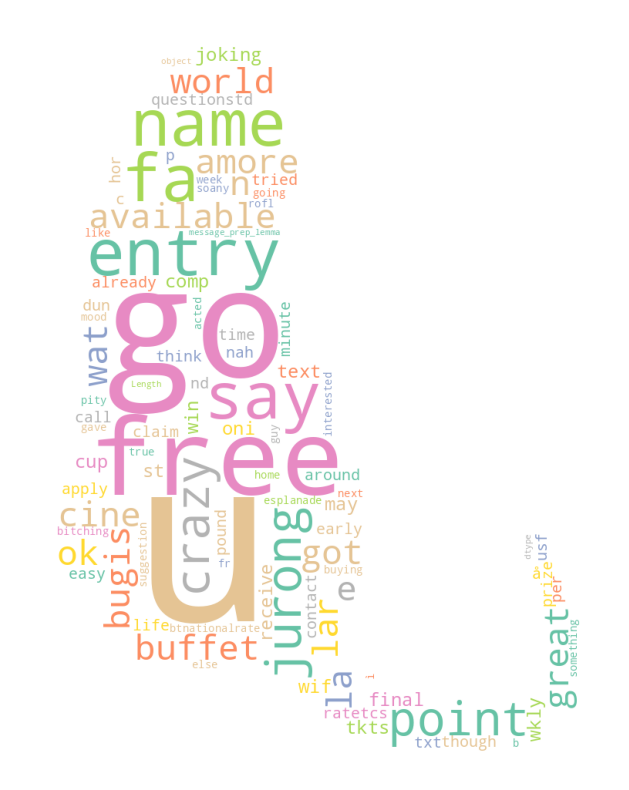

In [73]:
plot_cloud(wordcloud)

**SPAM**

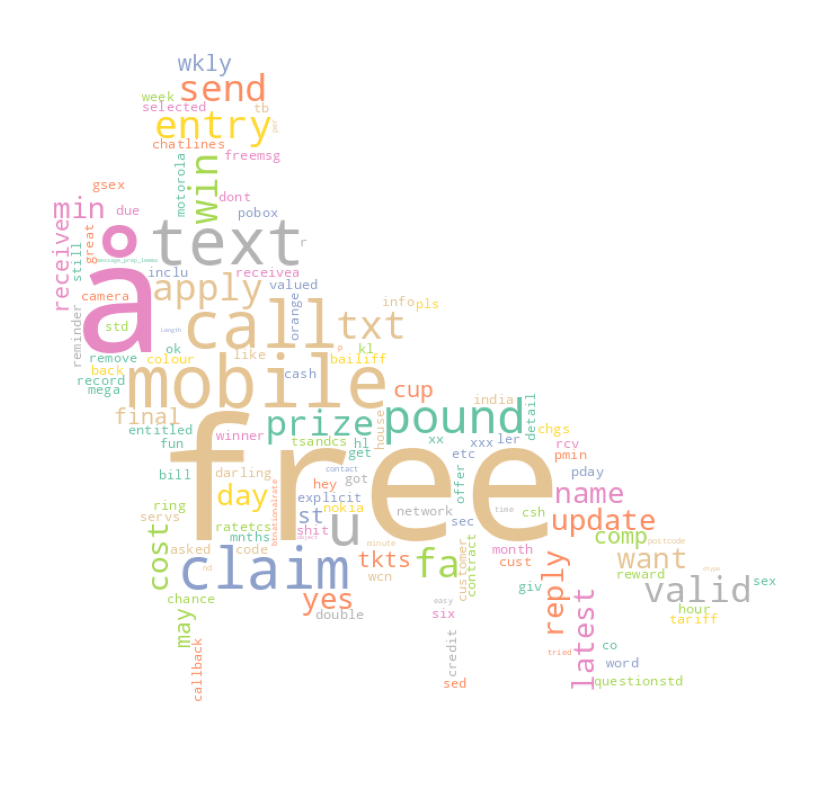

In [76]:
wordcloud_spam = WordCloud(  
                        random_state=1, 
                        max_font_size=300,
                        max_words=2000,
                        background_color='white', 
                        colormap='Set2', 
                        collocations=False, 
                        stopwords = stopwords.words('english'), 
                        mask=spam_mask).generate(str(df_sms[df_sms['label'] == 'spam']['message_prep_lemma']))
plot_cloud(wordcloud_spam)

**NON SPAM**

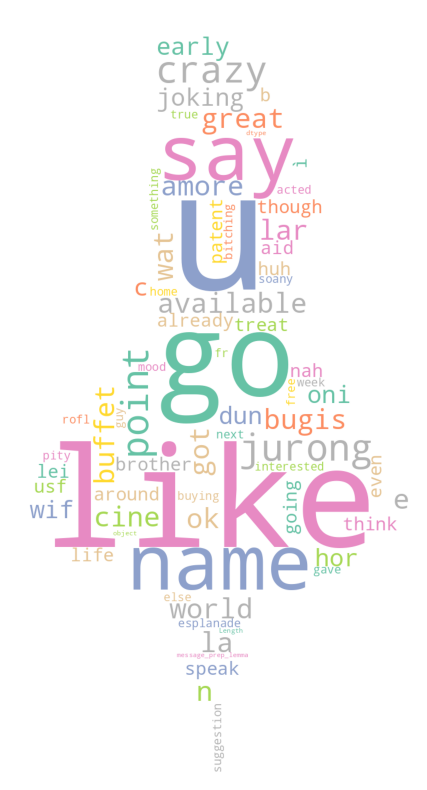

In [77]:
wordcloud_non_spam = WordCloud(  
                        random_state=1, 
                        max_font_size=300,
                        max_words=2000,
                        background_color='white', 
                        colormap='Set2', 
                        collocations=False, 
                        stopwords = stopwords.words('english'), 
                        mask=non_spam_mask).generate(str(df_sms[df_sms['label'] == 'ham']['message_prep_lemma']))
plot_cloud(wordcloud_non_spam)

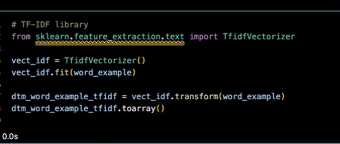

In [ ]:
# TF-IDF library
from sklearn.feature_extraction.text import TfidVectorizer

vect_idf = TfidVectorizer()
vect_idf.fit(word_example)

dtm_word_example_tfidf = vect_idf.transform(word_example)
dtm_word_example_tfidf.toarray()